# Sales & Product Segmentation (K-Means)

Tujuan: mengelompokkan produk berdasarkan karakteristik penjualannya.

- Input: `Items`, `TotalItem`, `NetSales`, `Outlet`, `Date`
- Metode: **K-Means Clustering**
- Output: kategori produk berdasarkan performa
  **Best Seller**, **Regular Seller**, **Seasonal Product**, **Slow Moving**

Setiap produk dicirikan oleh tujuh ukuran yang dihitung langsung dari transaksi:

| Fitur | Arti |
|---|---|
| `qty_per_day` | rata-rata item terjual per hari |
| `rev_per_day` | rata-rata NetSales per hari (kontribusi omzet) |
| `price_per_item` | NetSales dibagi jumlah item (nilai per item) |
| `cv_daily` | koefisien variasi penjualan harian (semakin besar semakin naik-turun) |
| `momentum` | kemiringan tren dibagi rata-rata harian (arah pertumbuhan) |
| `seasonal_strength` | kekuatan pola mingguan hasil dekomposisi STL |
| `weekend_ratio` | rata-rata akhir pekan dibagi hari kerja |

Hasil disimpan di `artifacts/product_segmentation/`.

## 1. Konfigurasi

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

DATA_PATH = Path("..") / "data" / "Transactions.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "product_segmentation"
MODEL_PATH = OUTPUT_DIR / "model.pkl"
METADATA_PATH = OUTPUT_DIR / "metadata.json"

CLUSTERS = 4        # jumlah kategori yang diminta
SEASON_LENGTH = 7   # pola mingguan
SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      :", pd.__version__)
print("folder hasil:", OUTPUT_DIR.resolve())

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


pandas      : 3.0.3
folder hasil: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\product_segmentation


## 2. Membongkar daftar item

Kolom `Items` berisi beberapa nama produk yang dipisah koma dalam satu struk.
Kolom itu dipecah supaya setiap baris mewakili satu item terjual.

In [2]:
transactions = pd.read_csv(DATA_PATH, parse_dates=["Date"])

lines = transactions[["Date", "Outlet", "Items", "TotalItem", "NetSales"]].copy()
lines["ProductName"] = lines.Items.str.split(",")
lines = lines.explode("ProductName")
lines["ProductName"] = lines.ProductName.str.strip()
lines["one"] = 1

assert lines.ProductName.notna().all(), "ada nama produk kosong"
assert len(lines) == transactions.TotalItem.sum(), "jumlah baris tidak sama dengan TotalItem"

print(f"baris transaksi asli   : {len(transactions):,}")
print(f"baris item setelah pecah: {len(lines):,}")
print(f"jumlah produk unik     : {lines.ProductName.nunique()}")
print(f"rentang tanggal        : {lines.Date.min().date()} s/d {lines.Date.max().date()}")

baris transaksi asli   : 53,820
baris item setelah pecah: 61,973
jumlah produk unik     : 94
rentang tanggal        : 2025-01-02 s/d 2025-09-30


## 3. Matriks produk x hari

Tabel ini menjadi sumber semua fitur: baris = tanggal, kolom = produk, isi = jumlah item terjual.

In [3]:
matrix = (
    lines.pivot_table(index="Date", columns="ProductName", values="one", aggfunc="sum")
    .asfreq("D")
    .fillna(0)
)

print("bentuk matriks produk x hari:", matrix.shape)
print(f"hari tanpa penjualan sama sekali: {int((matrix.sum(axis=1) == 0).sum())}")
print()
print(matrix.iloc[:3, :5].astype(int).to_string())

bentuk matriks produk x hari: (272, 94)
hari tanpa penjualan sama sekali: 0

ProductName  Air Mineral  Americano (Hot Arabica)  Americano (Hot Houseblend)  Americano (Ice Arabica)  Americano (Ice Houesblend)
Date                                                                                                                              
2025-01-02             2                        3                           2                        2                           3
2025-01-03             2                        3                           3                        4                           2
2025-01-04             0                        2                           4                        4                           3


## 4. Membentuk fitur tiap produk

Semua angka di bawah dihitung dari transaksi, tidak ada nilai yang dikarang.

In [4]:
import numpy as np

revenue = lines.groupby("ProductName").NetSales.sum()
quantity = matrix.sum()

features = pd.DataFrame({"quantity": quantity, "revenue": revenue})
features["qty_per_day"] = features.quantity / len(matrix)
features["rev_per_day"] = features.revenue / len(matrix)
features["price_per_item"] = features.revenue / features.quantity
features["cv_daily"] = matrix.std() / matrix.mean()
features["active_ratio"] = (matrix > 0).mean()
features["weekend_ratio"] = (
    matrix[matrix.index.dayofweek >= 5].mean() / matrix[matrix.index.dayofweek < 5].mean()
)
features["trend_slope"] = [
    np.polyfit(np.arange(len(matrix)), matrix[product].rolling(7, min_periods=1).mean(), 1)[0]
    for product in matrix.columns
]
features["momentum"] = features.trend_slope / features.qty_per_day * 100

print(f"produk dianalisis: {len(features)}")
print()
print(features[["quantity", "revenue", "price_per_item", "cv_daily", "weekend_ratio", "momentum"]].describe().round(2).to_string())

produk dianalisis: 94

       quantity      revenue  price_per_item  cv_daily  weekend_ratio  momentum
count     94.00        94.00           94.00     94.00          94.00     94.00
mean     659.29  16041671.54        24322.19      0.66           1.00      0.03
std       26.43   3603157.32         5312.59      0.03           0.09      0.05
min      590.00   5653153.37         8099.07      0.57           0.81     -0.10
25%      641.75  15218243.34        23454.30      0.64           0.93     -0.00
50%      657.00  16468468.60        25016.52      0.67           1.00      0.03
75%      679.75  17852702.84        26707.67      0.68           1.06      0.07
max      715.00  22018018.03        31485.97      0.75           1.21      0.13


In [5]:
from statsmodels.tsa.seasonal import STL

strength = []
for product in matrix.columns:
    series = matrix[product]
    decomposition = STL(series, period=SEASON_LENGTH, robust=True).fit()
    strength.append(max(0.0, 1 - decomposition.resid.var() / series.var()))

features["seasonal_strength"] = strength

print("kekuatan pola mingguan per produk:")
print(features.seasonal_strength.describe().round(3).to_string())

kekuatan pola mingguan per produk:
count    94.000
mean      0.289
std       0.072
min       0.120
25%       0.238
50%       0.289
75%       0.334
max       0.436


In [6]:
print("Sebaran antar produk (nilai terbesar dibagi terkecil):")
for column in ["quantity", "revenue", "price_per_item", "cv_daily", "weekend_ratio", "seasonal_strength"]:
    ratio = features[column].max() / features[column].min()
    print(f"  {column:<18} {ratio:>5.2f}x")
print()
print("Catatan: sebaran quantity hanya sekitar 1.2x, artinya semua produk terjual")
print("dalam jumlah yang hampir sama. Yang membedakan produk terutama nilai per item,")
print("arah tren, dan pola akhir pekan.")

Sebaran antar produk (nilai terbesar dibagi terkecil):
  quantity            1.21x
  revenue             3.89x
  price_per_item      3.89x
  cv_daily            1.30x
  weekend_ratio       1.50x
  seasonal_strength   3.63x

Catatan: sebaran quantity hanya sekitar 1.2x, artinya semua produk terjual
dalam jumlah yang hampir sama. Yang membedakan produk terutama nilai per item,
arah tren, dan pola akhir pekan.


## 5. Standarisasi fitur

K-Means memakai jarak, sehingga semua fitur disamakan skalanya lebih dulu.

In [7]:
from sklearn.preprocessing import StandardScaler

FEATURES = [
    "qty_per_day",
    "rev_per_day",
    "price_per_item",
    "cv_daily",
    "momentum",
    "seasonal_strength",
    "weekend_ratio",
]

scaler = StandardScaler()
X = scaler.fit_transform(features[FEATURES])

print("bentuk data latih:", X.shape)
print("rata-rata setelah standarisasi:", np.round(X.mean(axis=0), 3).tolist())
print("simpangan baku setelah standarisasi:", np.round(X.std(axis=0), 3).tolist())

bentuk data latih: (94, 7)
rata-rata setelah standarisasi: [0.0, -0.0, 0.0, -0.0, -0.0, 0.0, -0.0]
simpangan baku setelah standarisasi: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 6. Memilih jumlah cluster

Dua ukuran dipakai: **inertia** (untuk elbow) dan **silhouette** (semakin tinggi semakin rapat).

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

search = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    search.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, model.labels_),
        "ukuran_cluster": np.bincount(model.labels_).tolist(),
    })

search_table = pd.DataFrame(search)
print(search_table.round(3).to_string(index=False))

  File "C:\Users\Radit\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Radit\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Radit\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Radit\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


 k  inertia  silhouette              ukuran_cluster
 2  518.141       0.278                    [16, 78]
 3  433.063       0.174                [36, 16, 42]
 4  386.119       0.172            [29, 16, 30, 19]
 5  349.529       0.184        [20, 24, 16, 20, 14]
 6  319.432       0.185    [20, 16, 18, 16, 14, 10]
 7  303.059       0.168 [4, 14, 19, 11, 12, 13, 21]


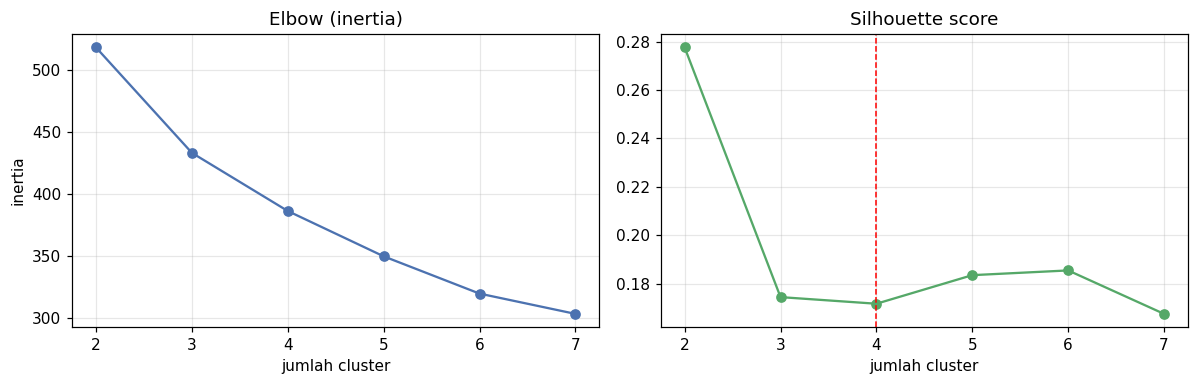

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].plot(search_table.k, search_table.inertia, marker="o", color="#4c72b0")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("jumlah cluster")
axes[0].set_ylabel("inertia")

axes[1].plot(search_table.k, search_table.silhouette, marker="o", color="#55a868")
axes[1].axvline(CLUSTERS, ls="--", color="red", lw=1)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("jumlah cluster")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_elbow_silhouette.png", dpi=120)
plt.show()

In [10]:
print(f"k terpilih: {CLUSTERS}")
print()
print("Alasan: kebutuhan bisnis meminta empat kategori produk. Pada k=4 kurva inertia")
print("mulai melandai dan ukuran cluster cukup berimbang, sehingga struktur empat")
print("kelompok masih bisa dibaca. Silhouette seluruh k bernilai rendah (di bawah 0.30),")
print("yang berarti batas antar kelompok tidak tajam. Hal ini wajar karena sebaran")
print("penjualan antar produk memang sempit, jadi hasil segmentasi dibaca sebagai")
print("kecenderungan, bukan pemisahan yang tegas.")

k terpilih: 4

Alasan: kebutuhan bisnis meminta empat kategori produk. Pada k=4 kurva inertia
mulai melandai dan ukuran cluster cukup berimbang, sehingga struktur empat
kelompok masih bisa dibaca. Silhouette seluruh k bernilai rendah (di bawah 0.30),
yang berarti batas antar kelompok tidak tajam. Hal ini wajar karena sebaran
penjualan antar produk memang sempit, jadi hasil segmentasi dibaca sebagai
kecenderungan, bukan pemisahan yang tegas.


## 7. Melatih K-Means

In [11]:
kmeans = KMeans(n_clusters=CLUSTERS, n_init=50, random_state=SEED).fit(X)

features["cluster"] = kmeans.labels_

print(f"inertia akhir     : {kmeans.inertia_:.2f}")
print(f"silhouette akhir  : {silhouette_score(X, kmeans.labels_):.3f}")
print()
print("jumlah produk per cluster:")
print(features.cluster.value_counts().sort_index().to_string())

inertia akhir     : 386.12
silhouette akhir  : 0.172

jumlah produk per cluster:


cluster
0    29
1    16
2    30
3    19


## 8. Membaca isi tiap cluster

Rata-rata fitur per cluster menunjukkan sifat khas masing-masing kelompok.

In [12]:
profile = features.groupby("cluster")[FEATURES].mean()
profile["jumlah_produk"] = features.groupby("cluster").size()
profile["total_item"] = features.groupby("cluster").quantity.sum()
profile["total_omzet"] = features.groupby("cluster").revenue.sum()
profile["share_omzet_%"] = profile.total_omzet / features.revenue.sum() * 100

print("Profil rata-rata per cluster:")
print(profile[FEATURES].round(3).to_string())
print()
print(profile[["jumlah_produk", "total_item", "total_omzet", "share_omzet_%"]].round(1).to_string())

Profil rata-rata per cluster:
         qty_per_day  rev_per_day  price_per_item  cv_daily  momentum  seasonal_strength  weekend_ratio
cluster                                                                                                
0              2.511    67430.857       26878.134     0.630     0.036              0.281          0.991
1              2.400    34836.422       14565.739     0.669     0.012              0.322          1.009
2              2.367    62145.602       26271.128     0.676     0.022              0.286          1.076
3              2.401    61398.279       25559.689     0.682     0.053              0.279          0.884

         jumlah_produk  total_item  total_omzet  share_omzet_%
cluster                                                       
0                   29     19806.0  531894596.8           35.3
1                   16     10446.0  151608109.4           10.1
2                   30     19311.0  507108111.0           33.6
3                   19     124

## 9. Memberi nama kategori

Nama ditentukan dari peringkat angka, bukan ditebak:

1. cluster dengan **omzet per hari tertinggi** menjadi **Best Seller**;
2. cluster dengan **omzet per hari terendah** menjadi **Slow Moving**;
3. dari dua cluster tengah, yang **rasio akhir pekannya lebih tinggi** menjadi **Seasonal Product**, sisanya **Regular Seller**.

Bukti angkanya dicetak di bawah agar bisa diperiksa.

In [13]:
order_revenue = profile.rev_per_day.sort_values(ascending=False).index.tolist()
middle = order_revenue[1:-1]

best_cluster = order_revenue[0]
slow_cluster = order_revenue[-1]
seasonal_cluster = max(middle, key=lambda cluster: profile.loc[cluster, "weekend_ratio"])
regular_cluster = [cluster for cluster in middle if cluster != seasonal_cluster][0]

label_map = {
    best_cluster: "Best Seller",
    regular_cluster: "Regular Seller",
    seasonal_cluster: "Seasonal Product",
    slow_cluster: "Slow Moving",
}

features["segment"] = features.cluster.map(label_map)

evidence = profile[["rev_per_day", "qty_per_day", "price_per_item", "momentum", "seasonal_strength", "weekend_ratio"]].copy()
evidence.insert(0, "segment", [label_map[cluster] for cluster in evidence.index])
print("Bukti penetapan nama (rata-rata per cluster):")
print(evidence.round(3).to_string())

Bukti penetapan nama (rata-rata per cluster):
                  segment  rev_per_day  qty_per_day  price_per_item  momentum  seasonal_strength  weekend_ratio
cluster                                                                                                        
0             Best Seller    67430.857        2.511       26878.134     0.036              0.281          0.991
1             Slow Moving    34836.422        2.400       14565.739     0.012              0.322          1.009
2        Seasonal Product    62145.602        2.367       26271.128     0.022              0.286          1.076
3          Regular Seller    61398.279        2.401       25559.689     0.053              0.279          0.884


In [14]:
segment_profile = features.groupby("segment")[FEATURES].mean()
segment_profile["jumlah_produk"] = features.groupby("segment").size()
segment_profile["share_item_%"] = features.groupby("segment").quantity.sum() / features.quantity.sum() * 100
segment_profile["share_omzet_%"] = features.groupby("segment").revenue.sum() / features.revenue.sum() * 100
segment_profile = segment_profile.loc[["Best Seller", "Regular Seller", "Seasonal Product", "Slow Moving"]]

print(segment_profile.round(2).to_string())

                  qty_per_day  rev_per_day  price_per_item  cv_daily  momentum  seasonal_strength  weekend_ratio  jumlah_produk  share_item_%  share_omzet_%
segment                                                                                                                                                     
Best Seller              2.51     67430.86        26878.13      0.63      0.04               0.28           0.99             29         31.96          35.27
Regular Seller           2.40     61398.28        25559.69      0.68      0.05               0.28           0.88             19         20.02          21.04
Seasonal Product         2.37     62145.60        26271.13      0.68      0.02               0.29           1.08             30         31.16          33.63
Slow Moving              2.40     34836.42        14565.74      0.67      0.01               0.32           1.01             16         16.86          10.05


## 10. Visualisasi hasil

Tiga gambar: sebaran cluster pada dua komponen utama, profil per kategori, dan kontribusi omzet.

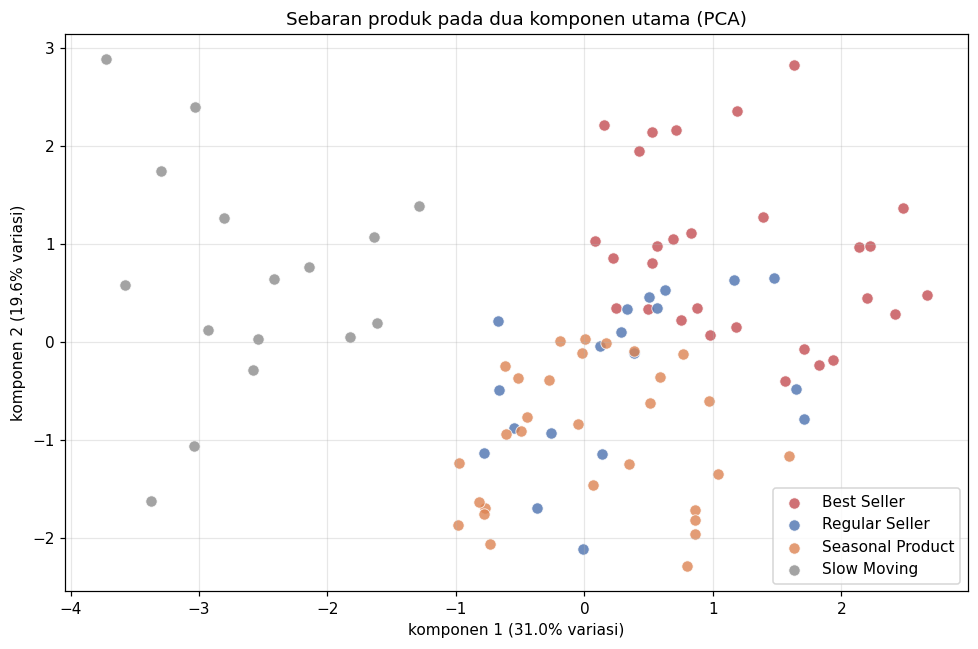

total variasi dua komponen: 50.6%


In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)
features["pca_1"] = coords[:, 0]
features["pca_2"] = coords[:, 1]

colors = {
    "Best Seller": "#c44e52",
    "Regular Seller": "#4c72b0",
    "Seasonal Product": "#dd8452",
    "Slow Moving": "#8c8c8c",
}

fig, ax = plt.subplots(figsize=(9, 6))
for segment, group in features.groupby("segment"):
    ax.scatter(group.pca_1, group.pca_2, s=55, alpha=0.8, label=segment, color=colors[segment], edgecolor="white", linewidth=0.6)
ax.set_title("Sebaran produk pada dua komponen utama (PCA)")
ax.set_xlabel(f"komponen 1 ({pca.explained_variance_ratio_[0]:.1%} variasi)")
ax.set_ylabel(f"komponen 2 ({pca.explained_variance_ratio_[1]:.1%} variasi)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_pca_scatter.png", dpi=120)
plt.show()

print("total variasi dua komponen:", f"{pca.explained_variance_ratio_.sum():.1%}")

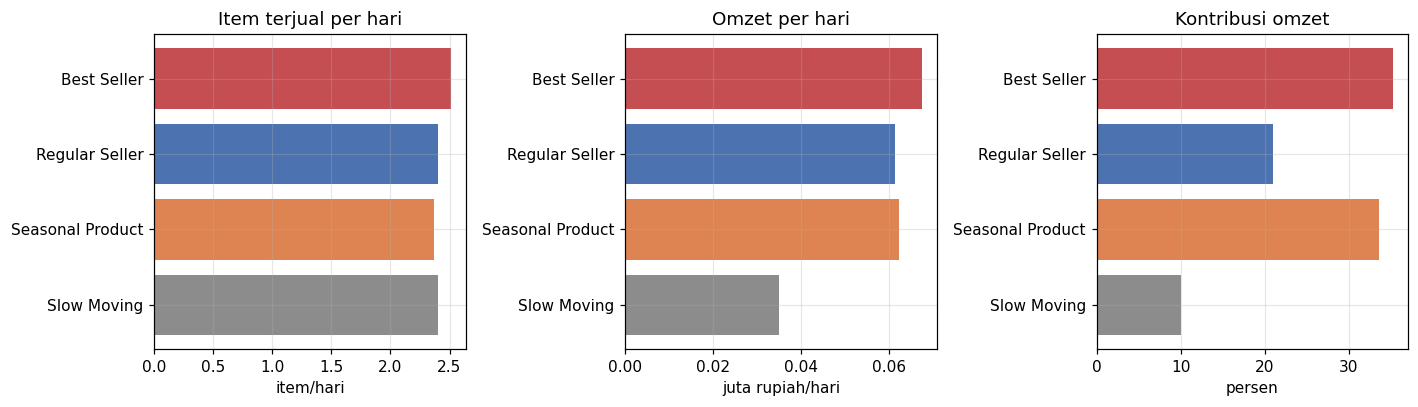

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].barh(segment_profile.index, segment_profile.qty_per_day, color=[colors[name] for name in segment_profile.index])
axes[0].set_title("Item terjual per hari")
axes[0].set_xlabel("item/hari")
axes[0].invert_yaxis()

axes[1].barh(segment_profile.index, segment_profile.rev_per_day / 1e6, color=[colors[name] for name in segment_profile.index])
axes[1].set_title("Omzet per hari")
axes[1].set_xlabel("juta rupiah/hari")
axes[1].invert_yaxis()

axes[2].barh(segment_profile.index, segment_profile["share_omzet_%"], color=[colors[name] for name in segment_profile.index])
axes[2].set_title("Kontribusi omzet")
axes[2].set_xlabel("persen")
axes[2].invert_yaxis()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_segment_profile.png", dpi=120)
plt.show()

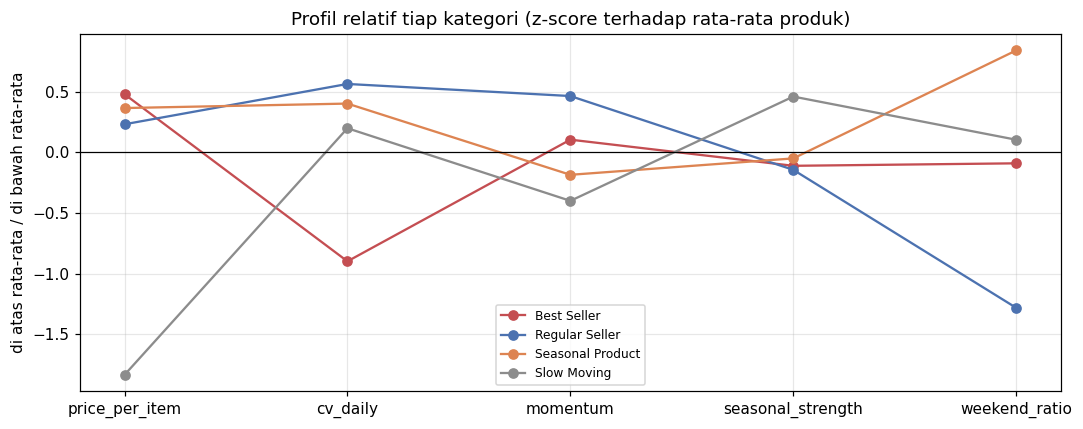

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_features = ["price_per_item", "cv_daily", "momentum", "seasonal_strength", "weekend_ratio"]
normalized = (segment_profile[plot_features] - features[plot_features].mean()) / features[plot_features].std()

for segment in normalized.index:
    ax.plot(plot_features, normalized.loc[segment], marker="o", label=segment, color=colors[segment])

ax.axhline(0, color="black", lw=0.8)
ax.set_title("Profil relatif tiap kategori (z-score terhadap rata-rata produk)")
ax.set_ylabel("di atas rata-rata / di bawah rata-rata")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_relative_profile.png", dpi=120)
plt.show()

## 11. Daftar produk per kategori

Setiap kategori ditampilkan beserta produk dengan omzet tertinggi di dalamnya.

In [18]:
for segment in ["Best Seller", "Regular Seller", "Seasonal Product", "Slow Moving"]:
    group = features[features.segment == segment].sort_values("revenue", ascending=False)
    print("=" * 70)
    print(f"{segment} - {len(group)} produk, omzet Rp {group.revenue.sum():,.0f} ({group.revenue.sum() / features.revenue.sum():.1%})")
    print(group[["quantity", "revenue", "price_per_item", "momentum"]].head(5).round(1).to_string())
    print()

Best Seller - 29 produk, omzet Rp 531,894,597 (35.3%)
                            quantity     revenue  price_per_item  momentum
ProductName                                                               
Chocolate (Gedhe)              700.0  22018018.0         31454.3       0.0
Hazelnut Latte (Gedhe)         692.0  21788288.3         31486.0       0.0
Not Tiramisu Latte (Gedhe)     698.0  21382882.9         30634.5      -0.0
Green Thai Tea (Gedhe)         687.0  21349549.6         31076.5       0.1
WHITE (Houseblend)             688.0  21333333.3         31007.8       0.1

Regular Seller - 19 produk, omzet Rp 317,306,308 (21.0%)
                       quantity     revenue  price_per_item  momentum
ProductName                                                          
Happy Moca (Ice)          664.0  20762162.2         31268.3      -0.0
Candy Latte (Gedhe)       646.0  19860360.4         30743.6       0.1
Chocolate (Ice)           693.0  19262162.4         27795.3       0.1
Friendly Coff

## 12. Ekspor model ke pickle

Yang disimpan: `StandardScaler`, model `KMeans`, daftar fitur, pemetaan nama kategori, dan titik pusat cluster.
Dengan begitu produk baru bisa langsung dipetakan ke kategori yang sama.

In [19]:
bundle = {
    "name": "K-Means product segmentation",
    "scaler": scaler,
    "model": kmeans,
    "feature_names": FEATURES,
    "label_map": {int(cluster): label for cluster, label in label_map.items()},
    "centroids": pd.DataFrame(
        scaler.inverse_transform(kmeans.cluster_centers_),
        columns=FEATURES,
        index=[label_map[cluster] for cluster in range(CLUSTERS)],
    ),
    "n_products": int(len(features)),
    "silhouette": float(silhouette_score(X, kmeans.labels_)),
    "inertia": float(kmeans.inertia_),
    "reference_date": str(matrix.index.max().date()),
}

with open(MODEL_PATH, "wb") as file:
    pickle.dump(bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"lokasi berkas : {MODEL_PATH}")
print(f"ukuran berkas : {MODEL_PATH.stat().st_size / 1024:,.1f} KB")
print(f"isi           : scaler, model KMeans, {len(FEATURES)} fitur, {len(label_map)} kategori")

lokasi berkas : ..\artifacts\product_segmentation\model.pkl
ukuran berkas : 3.3 KB
isi           : scaler, model KMeans, 7 fitur, 4 kategori


## 13. Menyimpan metadata

In [20]:
metadata = {
    "project": "MyVentory sales and product segmentation",
    "method": "K-Means Clustering",
    "inputs": ["Items", "TotalItem", "NetSales", "Outlet", "Date"],
    "source": {
        "file": "data/Transactions.csv",
        "rows": int(len(transactions)),
        "outlets": sorted(transactions.Outlet.unique().tolist()),
    },
    "period": {
        "start": str(matrix.index.min().date()),
        "end": str(matrix.index.max().date()),
        "days": int(len(matrix)),
    },
    "products": int(len(features)),
    "features": {name: description for name, description in {
        "qty_per_day": "rata-rata item terjual per hari",
        "rev_per_day": "rata-rata NetSales per hari",
        "price_per_item": "NetSales dibagi jumlah item",
        "cv_daily": "koefisien variasi penjualan harian",
        "momentum": "kemiringan tren dibagi rata-rata harian",
        "seasonal_strength": "kekuatan pola mingguan dari STL",
        "weekend_ratio": "rata-rata akhir pekan dibagi hari kerja",
    }.items()},
    "clustering": {
        "cluster_count": CLUSTERS,
        "random_state": SEED,
        "n_init": 50,
        "silhouette": round(float(silhouette_score(X, kmeans.labels_)), 4),
        "inertia": round(float(kmeans.inertia_), 2),
        "silhouette_by_k": {int(row.k): round(float(row.silhouette), 4) for row in search_table.itertuples()},
    },
    "segments": {
        name: {
            "products": int((features.segment == name).sum()),
            "qty_per_day": round(float(segment_profile.loc[name, "qty_per_day"]), 2),
            "rev_per_day": round(float(segment_profile.loc[name, "rev_per_day"]), 0),
            "share_omzet_%": round(float(segment_profile.loc[name, "share_omzet_%"]), 2),
            "price_per_item": round(float(segment_profile.loc[name, "price_per_item"]), 0),
            "momentum": round(float(segment_profile.loc[name, "momentum"]), 4),
            "weekend_ratio": round(float(segment_profile.loc[name, "weekend_ratio"]), 4),
            "seasonal_strength": round(float(segment_profile.loc[name, "seasonal_strength"]), 4),
        }
        for name in segment_profile.index
    },
    "label_rule": (
        "Best Seller = cluster dengan rev_per_day tertinggi; Slow Moving = terendah; "
        "Seasonal Product = weekend_ratio tertinggi di antara dua cluster tengah; "
        "sisanya Regular Seller."
    ),
    "note": (
        "Sebaran quantity antar produk hanya sekitar 1.2x, sehingga kategori tidak "
        "dipisahkan oleh volume. Perbedaan utama berasal dari nilai per item, arah tren, "
        "dan pola akhir pekan. Silhouette rendah menunjukkan batas antar cluster tidak tajam."
    ),
    "saved_model": {
        "file": MODEL_PATH.name,
        "clusters": CLUSTERS,
        "feature_names": FEATURES,
    },
    "artifacts": [
        MODEL_PATH.name,
        METADATA_PATH.name,
        "product_segments.csv",
        "segment_profile.csv",
        "fig_1_elbow_silhouette.png",
        "fig_2_pca_scatter.png",
        "fig_3_segment_profile.png",
        "fig_4_relative_profile.png",
    ],
}

METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("metadata tersimpan:", METADATA_PATH)

metadata tersimpan: ..\artifacts\product_segmentation\metadata.json


## 14. Menyimpan hasil segmentasi

In [21]:
segments_table = features.reset_index().rename(columns={"index": "product", "ProductName": "product"})
segments_table = segments_table.sort_values(["segment", "revenue"], ascending=[True, False])

columns = ["product", "segment", "cluster", "quantity", "revenue", "qty_per_day", "rev_per_day", "price_per_item",
           "cv_daily", "momentum", "seasonal_strength", "weekend_ratio", "active_ratio"]
segments_table[columns].round(4).to_csv(OUTPUT_DIR / "product_segments.csv", index=False)
segment_profile.round(4).to_csv(OUTPUT_DIR / "segment_profile.csv")

print(f"isi folder {OUTPUT_DIR.resolve()}:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:<32} {path.stat().st_size / 1024:>9.1f} KB")

isi folder C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\product_segmentation:
  fig_1_elbow_silhouette.png            45.8 KB
  fig_2_pca_scatter.png                 52.3 KB
  fig_3_segment_profile.png             26.6 KB
  fig_4_relative_profile.png            73.5 KB
  metadata.json                          3.2 KB
  model.pkl                              3.3 KB
  product_segments.csv                  10.9 KB
  segment_profile.csv                    0.5 KB


## 15. Verifikasi berkas pickle

Model dimuat ulang dari disk lalu dipakai mengelompokkan satu produk contoh.

In [22]:
with open(MODEL_PATH, "rb") as file:
    loaded = pickle.load(file)

sample_product = features.sort_values("revenue", ascending=False).index[0]
sample_row = features.loc[[sample_product], loaded["feature_names"]]
sample_scaled = loaded["scaler"].transform(sample_row)
sample_cluster = int(loaded["model"].predict(sample_scaled)[0])

print("berkas        :", MODEL_PATH.name)
print("algoritma     :", loaded["name"])
print("jumlah fitur  :", len(loaded["feature_names"]))
print("kategori      :", ", ".join(loaded["label_map"].values()))
print()
print(f"contoh produk : {sample_product}")
print(f"cluster       : {sample_cluster} -> {loaded['label_map'][sample_cluster]}")
print()
print("pusat cluster dalam satuan asli:")
centroid_table = pd.DataFrame(loaded["model"].cluster_centers_, columns=loaded["feature_names"])
centroid_table = pd.DataFrame(loaded["scaler"].inverse_transform(centroid_table), columns=loaded["feature_names"])
centroid_table.insert(0, "segment", [loaded["label_map"][cluster] for cluster in range(CLUSTERS)])
print(centroid_table.round(2).to_string(index=False))

berkas        : model.pkl
algoritma     : K-Means product segmentation
jumlah fitur  : 7
kategori      : Best Seller, Regular Seller, Seasonal Product, Slow Moving

contoh produk : Chocolate (Gedhe)
cluster       : 0 -> Best Seller

pusat cluster dalam satuan asli:
         segment  qty_per_day  rev_per_day  price_per_item  cv_daily  momentum  seasonal_strength  weekend_ratio
     Best Seller         2.51     67430.86        26878.13      0.63      0.04               0.28           0.99
     Slow Moving         2.40     34836.42        14565.74      0.67      0.01               0.32           1.01
Seasonal Product         2.37     62145.60        26271.13      0.68      0.02               0.29           1.08
  Regular Seller         2.40     61398.28        25559.69      0.68      0.05               0.28           0.88


## 16. Ringkasan

In [23]:
print("RINGKASAN HASIL")
print("-" * 62)
print(f"produk dianalisis : {len(features)}")
print(f"periode data      : {matrix.index.min().date()} s/d {matrix.index.max().date()} ({len(matrix)} hari)")
print(f"metode            : K-Means, k={CLUSTERS}, random_state={SEED}")
print(f"silhouette        : {silhouette_score(X, kmeans.labels_):.3f}")
print()
for name in ["Best Seller", "Regular Seller", "Seasonal Product", "Slow Moving"]:
    count = int((features.segment == name).sum())
    share = segment_profile.loc[name, "share_omzet_%"]
    print(f"{name:<18} {count:>3} produk   omzet {share:>5.2f}%")
print()
print("berkas keluaran:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("  ", path.name)

RINGKASAN HASIL
--------------------------------------------------------------
produk dianalisis : 94
periode data      : 2025-01-02 s/d 2025-09-30 (272 hari)
metode            : K-Means, k=4, random_state=42
silhouette        : 0.172

Best Seller         29 produk   omzet 35.27%
Regular Seller      19 produk   omzet 21.04%
Seasonal Product    30 produk   omzet 33.63%
Slow Moving         16 produk   omzet 10.05%

berkas keluaran:
   fig_1_elbow_silhouette.png
   fig_2_pca_scatter.png
   fig_3_segment_profile.png
   fig_4_relative_profile.png
   metadata.json
   model.pkl
   product_segments.csv
   segment_profile.csv


## Export model ke API (berversion)

Model disalin ke `API/artifacts/product_segmentation/1.0.0/` sehingga versi lama tetap tersimpan dan bisa
dibandingkan. Versi juga ditulis ke `metadata.json` sebagai `model_version`.

In [24]:
import shutil

NOTEBOOK_NAME = "product_segmentation"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / "product_segmentation" / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads((OUTPUT_DIR / "metadata.json").read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": "product_segmentation",
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

shutil.copy2(OUTPUT_DIR / "model.pkl", API_DIR / "model.pkl")
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

product_segmentation versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\product_segmentation\1.0.0
   metadata.json              3.3 KB
   model.pkl                  3.3 KB
